<div style="background:#17365D; padding:22px; border-radius:12px; text-align:center; color:white;">
  <h1 style="color:#FFFFFF; margin:0 0 10px;">Customer Churn Risk Analysis</h1>
  <h3 style="color:#90E0EF; margin:0 0 10px;">Exploratory Data Analysis (EDA)</h3>
  <p style="color:#FFD166; font-size:16px; margin:0;"><b>DIET Path-1 | Manthan Hackathon</b></p>
  <p style="color:#FFFFFF; margin:12px 0 0;">Understanding customer churn and identifying opportunities to improve retention.</p>
</div>

## CBIM / problem framing canvas
- **Context:** A telecom provider wants to understand customer churn using an existing customer-level Q3 dataset.
- **Business problem:** Churn is material (baseline 26.53%); churned customers have higher average monthly charges, and the company needs to prioritise retention attention.
- **Insight question:** Which observable customer groups have elevated churn, what churn reasons are recorded, and what actions should be tested?
- **Data:** 4,225 customers, 52 columns, one quarter (Q3), churn flag plus demographic, tenure, contract, service, charge and exit-reason fields.
- **Decision user:** Customer retention / commercial operations team.
- **Success:** A reproducible EDA, transparent limitations, three priority segments, revenue-at-risk estimate and practical testable actions.
- **Scope boundary:** Descriptive EDA only. No predictive modelling, deep learning or clustering.

## 1. Load, audit and clean the dataset
We preserve the raw file, validate schema and key fields, and avoid deleting or imputing structurally missing values. `Churn Category` and `Churn Reason` are only expected for customers who churned; missing `Internet Type` aligns with no internet service; missing `Offer` is not assigned a guessed category.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load the customer data
raw = pd.read_csv("Customer_Churn.csv")
df = raw.copy()

# Basic data checks
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["Customer ID"].duplicated().sum())
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print("Churn counts:")
print(df["Churn"].value_counts(dropna=False))
print("Column data types:")
print(df.dtypes.value_counts())


Dataset shape: (4225, 52)
Duplicate rows: 0
Duplicate customer IDs: 0
Missing values:
Churn Category    3104
Churn Reason      3104
Internet Type      886
Offer             2324
dtype: int64
Churn counts:
Churn
0    3104
1    1121
Name: count, dtype: int64
Column data types:
int64      30
object     14
float64     8
Name: count, dtype: int64


In [3]:
# Validate the target and status consistency before analysis
assert df["Churn"].dropna().isin([0, 1]).all(), "Churn must be binary 0/1"
print(pd.crosstab(df["Customer Status"], df["Churn"], margins=True))
print("Internet Service vs Internet Type missingness:")
print(pd.crosstab(df["Internet Service"], df["Internet Type"].isna(), margins=True))

Churn               0     1   All
Customer Status                  
Churned             0  1121  1121
Joined            272     0   272
Stayed           2832     0  2832
All              3104  1121  4225
Internet Service vs Internet Type missingness:
Internet Type     False  True   All
Internet Service                   
0                     0   886   886
1                  3339     0  3339
All                3339   886  4225


**Cleaning decisions:** No exact duplicates or duplicate customer IDs were found, so no rows were removed. `Churn` is already numeric 0/1. The 3,104 missing churn-category and churn-reason values correspond to retained customers and are structurally expected. All 886 missing `Internet Type` values align with `Internet Service = 0`. `Offer` has 2,324 missing values; without a codebook proving the meaning, they remain missing and are not labelled “no offer”. Location identifiers are not used in public-facing analysis.

## 2. Define churn and measure the overall rate
The target definition is `Churn = 1` for churned customers and `Churn = 0` for all other records. `Customer Status` distinguishes Stayed, Churned and Joined; the 272 Joined records are coded 0 and remain in the dataset-wide denominator. We report this explicitly and include a sensitivity check excluding Joined customers.

In [4]:
churned = int(df["Churn"].sum())
total = len(df)
retained = total - churned
overall_rate = df["Churn"].mean()
print(f"Customers: {total:,}")
print(f"Churned: {churned:,} ({overall_rate:.2%})")
print(f"Not churned: {retained:,} ({1-overall_rate:.2%})")
joined = df["Customer Status"].eq("Joined")
print("Joined customers:", int(joined.sum()))
print("Churn rate excluding Joined:", f"{df.loc[~joined, 'Churn'].mean():.2%}")
print("Average monthly charge, retained:", f"${df.loc[df.Churn.eq(0), 'Monthly Charge'].mean():.2f}")
print("Average monthly charge, churned:", f"${df.loc[df.Churn.eq(1), 'Monthly Charge'].mean():.2f}")

Customers: 4,225
Churned: 1,121 (26.53%)
Not churned: 3,104 (73.47%)
Joined customers: 272
Churn rate excluding Joined: 28.36%
Average monthly charge, retained: $61.66
Average monthly charge, churned: $73.89


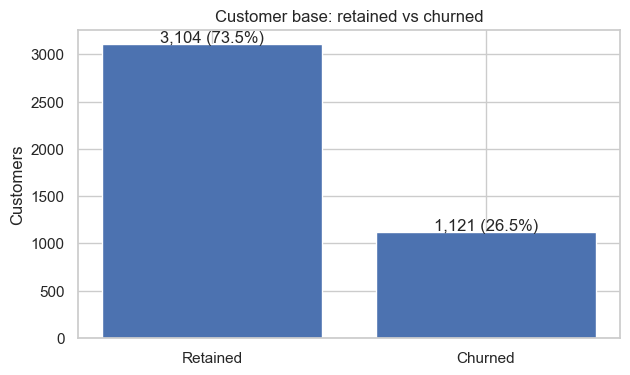

In [5]:
counts = df["Churn"].value_counts().reindex([0,1])
plt.figure(figsize=(7,4)); plt.bar(["Retained","Churned"], counts.values)
plt.title("Customer base: retained vs churned"); plt.ylabel("Customers")
for i,v in enumerate(counts.values): plt.text(i,v+20,f"{v:,} ({v/len(df):.1%})",ha="center")
plt.show()

**Interpretation:** 1,121 of 4,225 customers churned (26.53%). The churned group has a higher mean monthly charge ($73.89) than the non-churned group ($61.66). This is an association, not proof that higher charges caused departure. Because Joined customers are included in the official data-wide rate, we also disclose the 28.36% rate among non-Joined records.

## 3. Churn by customer tenure
Use the specified lifecycle bands: 0–12, 13–24, 25–48 and 49–72 months. Report both counts and within-band churn rates.

,Tenure Group,customers,churned,churn_rate
0,0–12 months,1303,620,47.6%
1,13–24 months,599,170,28.4%
2,25–48 months,963,208,21.6%
3,49–72 months,1360,123,9.0%


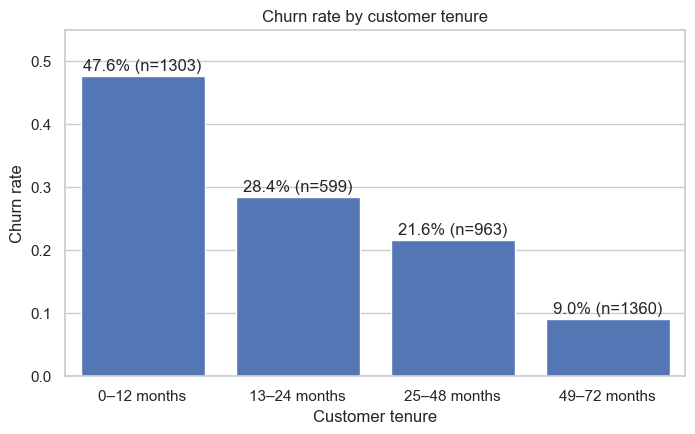

In [6]:
df["Tenure Group"] = pd.cut(df["Tenure in Months"], bins=[-1,12,24,48,72], labels=["0–12 months","13–24 months","25–48 months","49–72 months"], include_lowest=True)
tenure_summary = df.groupby("Tenure Group", observed=True)["Churn"].agg(customers="size", churned="sum", churn_rate="mean").reset_index()
display(tenure_summary.style.format({"churn_rate":"{:.1%}"}))
plt.figure(figsize=(8,4.5)); sns.barplot(data=tenure_summary,x="Tenure Group",y="churn_rate",color="#4472C4")
plt.title("Churn rate by customer tenure"); plt.xlabel("Customer tenure"); plt.ylabel("Churn rate"); plt.ylim(0,.55)
for i,r in tenure_summary.iterrows(): plt.text(i,r.churn_rate+.01,f"{r.churn_rate:.1%} (n={r.customers})",ha="center")
plt.show()

**Interpretation:** The 0–12 month group has the highest observed churn rate (47.58%, 620 of 1,303), and churn falls across the later tenure bands to 9.04% among customers with 49–72 months tenure. This supports prioritising early-lifecycle experience reviews, while recognising that cross-sectional data cannot establish when or why each customer decided to leave.

## 4. Contract, billing and payment method
For every category, show group size and churn rate. The rate denominator is customers within that category, not all churned customers.


 Contract


,customers,churned,churn_rate
Contract,,,
Month-to-Month,2193,997,45.5%
One Year,904,97,10.7%
Two Year,1128,27,2.4%



 Payment Method


,customers,churned,churn_rate
Payment Method,,,
Mailed Check,220,77,35.0%
Bank Withdrawal,2325,782,33.6%
Credit Card,1680,262,15.6%



 Paperless Billing


,customers,churned,churn_rate
Paperless Billing,,,
1,2503,845,33.8%
0,1722,276,16.0%


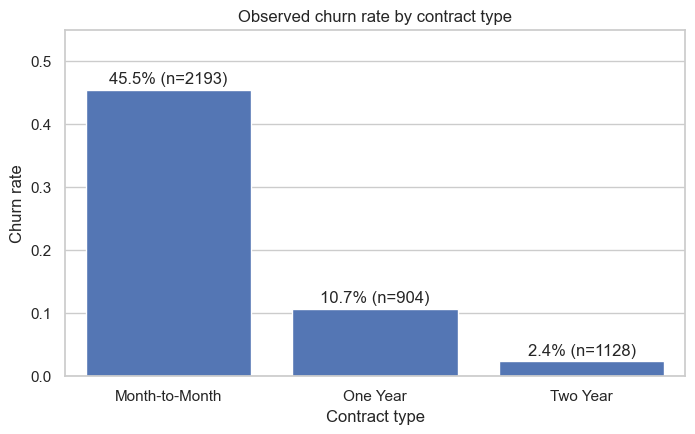

In [7]:
for col in ["Contract", "Payment Method", "Paperless Billing"]:
    summary = df.groupby(col, dropna=False)["Churn"].agg(customers="size", churned="sum", churn_rate="mean").sort_values("churn_rate", ascending=False)
    print("\n", col); display(summary.style.format({"churn_rate":"{:.1%}"}))
contract_summary = df.groupby("Contract")["Churn"].agg(customers="size",churned="sum",churn_rate="mean").reset_index().sort_values("churn_rate",ascending=False)
plt.figure(figsize=(8,4.5)); sns.barplot(data=contract_summary,x="Contract",y="churn_rate",color="#4472C4")
plt.title("Observed churn rate by contract type"); plt.ylabel("Churn rate"); plt.xlabel("Contract type"); plt.ylim(0,.55)
for i,r in contract_summary.reset_index(drop=True).iterrows(): plt.text(i,r.churn_rate+.01,f"{r.churn_rate:.1%} (n={r.customers})",ha="center")
plt.show()

**Interpretation:** Month-to-month customers have a 45.46% churn rate (997/2,193), compared with 10.73% for one-year contracts and 2.39% for two-year contracts. Paperless billing is associated with 33.76% churn versus 16.03% without it; mailed-check customers show 35.00% and bank-withdrawal customers 33.63%, versus 15.60% for credit-card customers. These are descriptive differences; contract duration, tenure, payment preferences and customer mix may be interrelated.

## 5. Internet and add-on services
Compare internet types and optional services. The no-internet group is retained as a meaningful category rather than dropped.

,Internet Type,customers,churned,churn_rate
0,Cable,502,124,24.7%
1,DSL,1008,200,19.8%
2,Fiber Optic,1829,733,40.1%
3,No internet service,886,64,7.2%


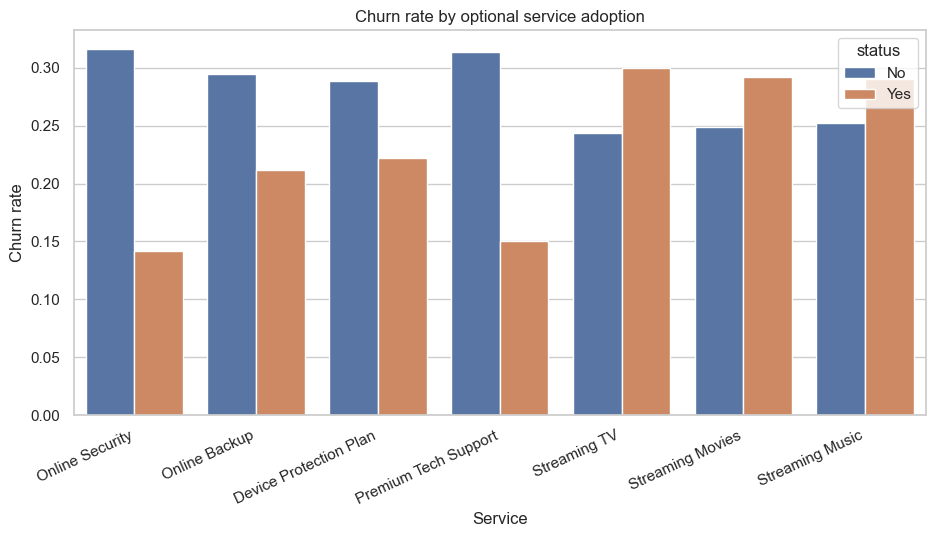

In [8]:
internet_summary = df.groupby("Internet Type",dropna=False)["Churn"].agg(customers="size",churned="sum",churn_rate="mean").reset_index()
internet_summary["Internet Type"] = internet_summary["Internet Type"].fillna("No internet service")
display(internet_summary.style.format({"churn_rate":"{:.1%}"}))
service_cols=["Online Security","Online Backup","Device Protection Plan","Premium Tech Support","Streaming TV","Streaming Movies","Streaming Music"]
service_rows=[]
for col in service_cols:
    for value,label in [(0,"No"),(1,"Yes")]:
        x=df.loc[df[col].eq(value)]
        service_rows.append({"service":col,"status":label,"customers":len(x),"churn_rate":x.Churn.mean()})
service_summary=pd.DataFrame(service_rows)
plt.figure(figsize=(11,5)); sns.barplot(data=service_summary,x="service",y="churn_rate",hue="status")
plt.title("Churn rate by optional service adoption"); plt.xlabel("Service"); plt.ylabel("Churn rate"); plt.xticks(rotation=25,ha="right"); plt.show()

**Interpretation:** Fiber Optic customers have a 40.08% churn rate, compared with 24.70% for Cable and 19.84% for DSL; customers without internet service show 7.22%. Lack of Online Security and Premium Tech Support is associated with higher churn (31.65% vs 14.16%, and 31.39% vs 15.00%, respectively). These patterns suggest investigating fibre experience and support/security value, not assuming that selling add-ons will automatically reduce churn.

## 6. Charges and revenue at risk
We compare Monthly Charge and Total Charges distributions, and estimate the monthly charges attached to customers marked as churned. This is a snapshot exposure proxy, not a forecast of realised revenue loss.

Monthly Charge        Total Charges           Total Revenue           \
                mean median          mean    median          mean   median   
Churn                                                                        
0          61.662436  64.80   2592.403947  1715.125   3470.195638  2636.32   
1          73.889028  79.35   1513.254371   676.700   1946.080384   899.72   

      Total Refunds         
               mean median  
Churn                       
0          2.134620    0.0  
1          1.453292    0.0

Monthly charges associated with churned customers: $82,829.60
Share of all recorded monthly charges: 30.20%


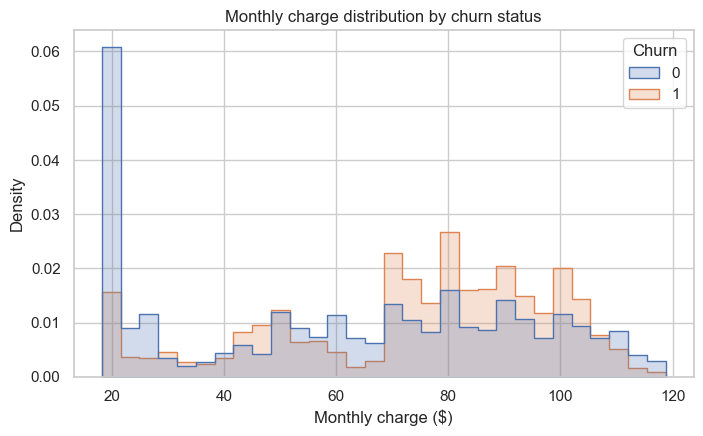

In [9]:
charge_stats = df.groupby("Churn")[["Monthly Charge","Total Charges","Total Revenue","Total Refunds"]].agg(["mean","median"])
display(charge_stats)
monthly_at_risk = df.loc[df.Churn.eq(1),"Monthly Charge"].sum()
monthly_total = df["Monthly Charge"].sum()
print(f"Monthly charges associated with churned customers: ${monthly_at_risk:,.2f}")
print(f"Share of all recorded monthly charges: {monthly_at_risk/monthly_total:.2%}")
plt.figure(figsize=(8,4.5)); sns.histplot(data=df,x="Monthly Charge",hue="Churn",bins=30,stat="density",common_norm=False,element="step")
plt.title("Monthly charge distribution by churn status"); plt.xlabel("Monthly charge ($)"); plt.ylabel("Density"); plt.show()

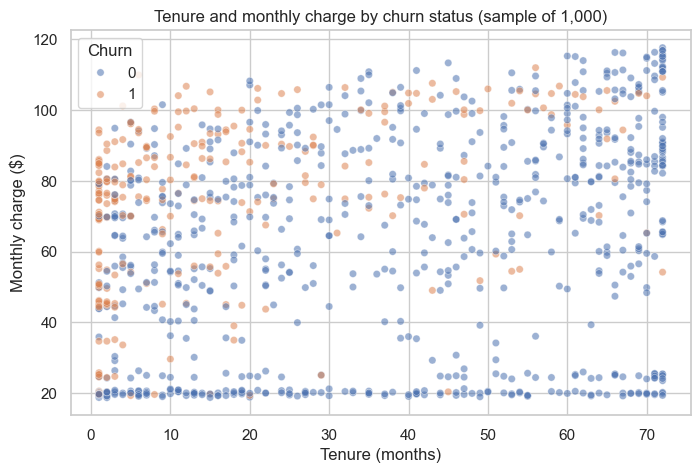

In [10]:
sample = df.sample(min(1000,len(df)),random_state=42)
plt.figure(figsize=(8,5)); sns.scatterplot(data=sample,x="Tenure in Months",y="Monthly Charge",hue="Churn",alpha=.55,s=28)
plt.title("Tenure and monthly charge by churn status (sample of 1,000)"); plt.xlabel("Tenure (months)"); plt.ylabel("Monthly charge ($)"); plt.show()

**Interpretation:** Churned customers account for $82,829.60 in recorded monthly charges, 30.20% of the $274,229.80 total. Their mean monthly charge is $73.89 versus $61.66 for non-churned customers. This is a gross monthly-charge exposure measure only: it is not net revenue, margin, lifetime value, nor a guaranteed amount that could be saved through retention.

## 7. Customer profiles and variable relationships
Review gender, age-related flags, senior-citizen, partner and dependent status. Use correlations as descriptive linear associations, not causal explanations. Exclude direct identifiers and location coordinates from the heatmap.

In [11]:
profile_cols=["Gender","Senior Citizen","Partner","Dependents","Under 30"]
for col in profile_cols:
    summary=df.groupby(col,dropna=False)["Churn"].agg(customers="size",churned="sum",churn_rate="mean").sort_values("churn_rate",ascending=False)
    print("\n",col); display(summary.style.format({"churn_rate":"{:.1%}"}))
# Example two-variable pivot: contract by tenure band
pivot=pd.pivot_table(df,index="Contract",columns="Tenure Group",values="Churn",aggfunc="mean",observed=True)
display(pivot.style.format("{:.1%}").background_gradient(cmap="Reds"))


 Gender


,customers,churned,churn_rate
Gender,,,
Female,2101,573,27.3%
Male,2124,548,25.8%



 Senior Citizen


,customers,churned,churn_rate
Senior Citizen,,,
1,696,279,40.1%
0,3529,842,23.9%



 Partner


,customers,churned,churn_rate
Partner,,,
0,2183,729,33.4%
1,2042,392,19.2%



 Dependents


,customers,churned,churn_rate
Dependents,,,
0,3240,1057,32.6%
1,985,64,6.5%



 Under 30


,customers,churned,churn_rate
Under 30,,,
0,3380,937,27.7%
1,845,184,21.8%


Tenure Group,0–12 months,13–24 months,25–48 months,49–72 months
Contract,,,,
Month-to-Month,53.4%,38.5%,38.6%,28.1%
One Year,5.6%,11.4%,10.4%,11.7%
Two Year,0.0%,0.0%,1.5%,3.1%


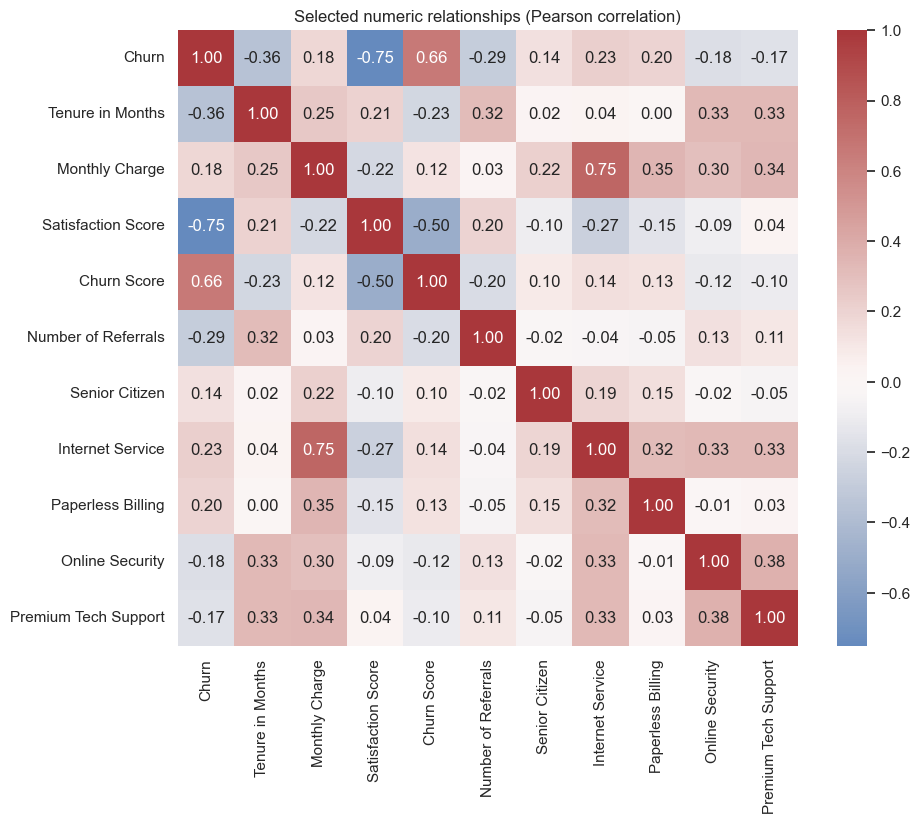

In [12]:
selected=["Churn","Tenure in Months","Monthly Charge","Satisfaction Score","Churn Score","Number of Referrals","Senior Citizen","Internet Service","Paperless Billing","Online Security","Premium Tech Support"]
plt.figure(figsize=(10,8)); sns.heatmap(df[selected].corr(numeric_only=True),annot=True,fmt=".2f",cmap="vlag",center=0)
plt.title("Selected numeric relationships (Pearson correlation)"); plt.show()

**Interpretation and leakage warning:** Churn has a strong negative correlation with Satisfaction Score (-0.75) and positive correlation with Churn Score (0.66). The satisfaction pattern is unusually deterministic in this file: all score-1 and score-2 records churned, while no score-4 or score-5 records churned. These fields may be recorded at/after the churn event or constructed using outcome information. They are useful for describing the supplied records, but should not be presented as proven pre-churn predictors. The contract-by-tenure pivot helps show that customer mix varies across both dimensions.

<div style="background:#18794E; color:white; padding:13px 18px; border-radius:9px;">
<h2 style="color:white; margin:0;">8. High-Risk Customer Segments & Business Recommendations</h2>
</div>

Identify customer groups with higher churn rates, compare them with the overall churn rate, and suggest **three practical business actions**. These groups can overlap, so their customer counts should not be added together.

In [13]:
segment_defs={
    "New tenure (0–12 months)":df["Tenure in Months"].between(0,12),
    "Fiber Optic internet":df["Internet Type"].eq("Fiber Optic"),
    "Month-to-month contract":df["Contract"].eq("Month-to-Month"),
    "New tenure + Fiber Optic":df["Tenure in Months"].between(0,12)&df["Internet Type"].eq("Fiber Optic"),
    "Month-to-month + Fiber Optic":df["Contract"].eq("Month-to-Month")&df["Internet Type"].eq("Fiber Optic"),
    "Month-to-month + new tenure":df["Contract"].eq("Month-to-Month")&df["Tenure in Months"].between(0,12),
    "Month-to-month + Fiber + new tenure":df["Contract"].eq("Month-to-Month")&df["Internet Type"].eq("Fiber Optic")&df["Tenure in Months"].between(0,12),
}
rows=[]
for name,mask in segment_defs.items():
    x=df.loc[mask]
    rows.append({"segment":name,"customers":len(x),"churned":int(x.Churn.sum()),"churn_rate":x.Churn.mean(),"lift_vs_baseline":x.Churn.mean()/df.Churn.mean()})
segment_table=pd.DataFrame(rows).sort_values(["churn_rate","customers"],ascending=[False,False])
display(segment_table.style.format({"churn_rate":"{:.1%}","lift_vs_baseline":"{:.2f}×"}))

,segment,customers,churned,churn_rate,lift_vs_baseline
6,Month-to-month + Fiber + new tenure,502,364,72.5%,2.73×
3,New tenure + Fiber Optic,533,364,68.3%,2.57×
4,Month-to-month + Fiber Optic,1145,664,58.0%,2.19×
5,Month-to-month + new tenure,1153,616,53.4%,2.01×
0,New tenure (0–12 months),1303,620,47.6%,1.79×
2,Month-to-month contract,2193,997,45.5%,1.71×
1,Fiber Optic internet,1829,733,40.1%,1.51×


### <span style="color:#2563EB;">8.1 Visualise High-Risk Groups</span>

This graph compares the **churn percentage** of the three highest-risk groups with the overall churn rate (red dashed line). The labels show each group's customer count (`n`).

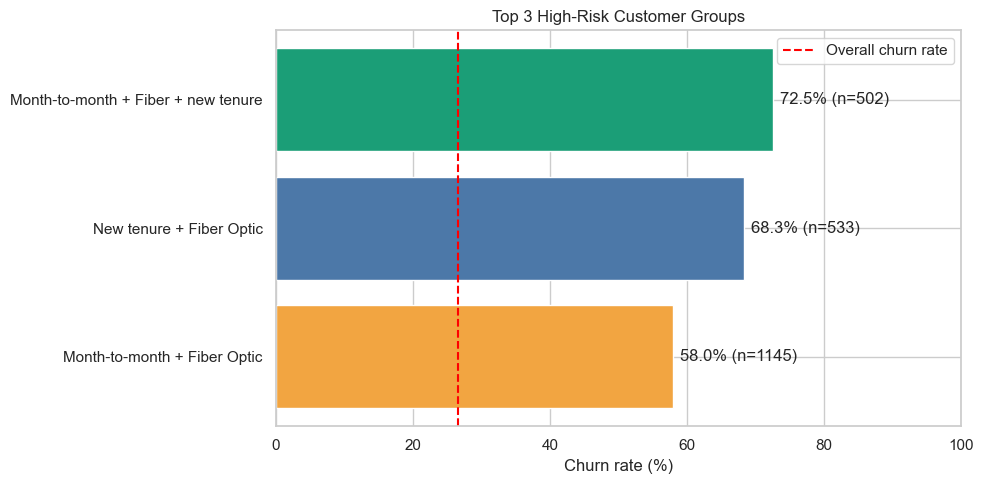

In [14]:
# Graph 1: Top 3 high-risk customer groups
high_risk = segment_table.head(3).copy()
plt.figure(figsize=(10, 5))
plt.barh(high_risk["segment"], high_risk["churn_rate"] * 100, color=["#1B9E77", "#4C78A8", "#F2A541"])
plt.axvline(df["Churn"].mean() * 100, color="red", linestyle="--", label="Overall churn rate")
for i, row in enumerate(high_risk.itertuples()):
    plt.text(row.churn_rate * 100 + 1, i, f"{row.churn_rate:.1%} (n={row.customers})", va="center")
plt.xlabel("Churn rate (%)")
plt.title("Top 3 High-Risk Customer Groups")
plt.xlim(0, max(100, high_risk["churn_rate"].max() * 100 + 20))
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### <span style="color:#2563EB;">8.2 Compare Churned Customer Counts</span>

A high churn percentage matters, but so does the number of customers affected. This graph shows how many customers churned in each group. **Groups overlap**, so these counts must not be added together.

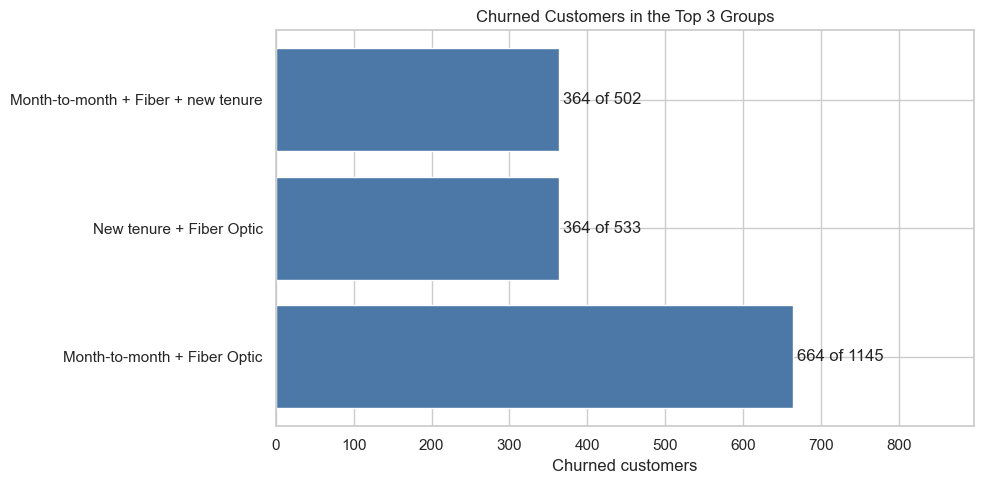

In [15]:
# Graph 2: Number of customers who churned in the top groups
plt.figure(figsize=(10, 5))
plt.barh(high_risk["segment"], high_risk["churned"], color="#4C78A8")
for i, row in enumerate(high_risk.itertuples()):
    plt.text(row.churned + 5, i, f"{row.churned} of {row.customers}", va="center")
plt.xlabel("Churned customers")
plt.title("Churned Customers in the Top 3 Groups")
plt.xlim(0, high_risk["churned"].max() * 1.35)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### <span style="color:#18794E;">8.3 Key Findings & Three Business Recommendations</span>

**Findings from the notebook**

- **Month-to-month + Fiber Optic + 0–12 months:** 364 of 502 customers churned (**72.51%**).
- **New tenure + Fiber Optic:** approximately **68.29%** churn.
- **Month-to-month + Fiber Optic:** approximately **57.99%** churn.

**Three business recommendations**(the one's asked in assignment)

1. **Improve new-customer onboarding.** Introduce check-ins during the first 30, 60 and 90 days to identify and resolve service issues early.
2. **Investigate Fiber Optic service experience.** Review installation, internet reliability, speed and support complaints, then address common issues.
3. **Offer targeted retention benefits.** Test suitable loyalty offers or transparent longer-term plans for month-to-month customers, while checking costs and customer preferences.

**Business takeaway:** Prioritise the early-tenure, month-to-month Fiber Optic group for investigation and small retention pilots. These are observed associations, **not proof of what causes churn** or guaranteed results from the proposed actions.

## Final executive conclusion
The dataset-wide churn rate is 26.53%. Churn is concentrated among early-tenure customers and customers on month-to-month contracts; the most acute observed segment is month-to-month Fiber Optic customers in their first 12 months (72.51%, n=502). Competitor reasons account for 486 of 1,121 churned customers (43.35%). Churned customers represent $82,829.60 of recorded monthly charges (30.20% of total), a gross exposure estimate. The business should prioritise early-lifecycle fibre experience and competitive value reviews, then test targeted retention actions while measuring margin and actual retention outcomes.